In [25]:
import pandas as pd

# Charger le jeu de données (remplacez 'car_data.csv' par le chemin réel de votre fichier)
try:
    df = pd.read_csv('USA_cars_datasets.csv')
    print("Données chargées avec succès!")
except FileNotFoundError:
    print("Erreur: Le fichier 'car_data.csv' n'a pas été trouvé. Veuillez vérifier le chemin ou le nom du fichier.")
    exit()

# Afficher les 5 premières lignes
print("\n--- Premières lignes du jeu de données ---")
print(df.head())

# Afficher les informations générales sur le jeu de données (types de données, valeurs non nulles)
print("\n--- Informations sur le jeu de données ---")
print(df.info())

# Afficher les statistiques descriptives
print("\n--- Statistiques descriptives ---")
print(df.describe())
print("\nForme du jeu de données avant nettoyage:", df.shape)

Données chargées avec succès!

--- Premières lignes du jeu de données ---
   Unnamed: 0  price      brand    model  year   title_status   mileage  \
0           0   6300     toyota  cruiser  2008  clean vehicle  274117.0   
1           1   2899       ford       se  2011  clean vehicle  190552.0   
2           2   5350      dodge      mpv  2018  clean vehicle   39590.0   
3           3  25000       ford     door  2014  clean vehicle   64146.0   
4           4  27700  chevrolet     1500  2018  clean vehicle    6654.0   

    color                  vin        lot       state country      condition  
0   black    jtezu11f88k007763  159348797  new jersey     usa   10 days left  
1  silver    2fmdk3gc4bbb02217  166951262   tennessee     usa    6 days left  
2  silver    3c4pdcgg5jt346413  167655728     georgia     usa    2 days left  
3    blue    1ftfw1et4efc23745  167753855    virginia     usa  22 hours left  
4     red    3gcpcrec2jg473991  167763266     florida     usa  22 hours left  



In [26]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Gérer les valeurs manquantes (exemple simple: supprimer les lignes avec des NaN)
# Utilisez df.fillna() pour l'imputation si vous préférez ne pas supprimer.
df_cleaned = df.dropna()

# Suppression des doublons
df_cleaned = df_cleaned.drop_duplicates()

#Suppression des colonnes inutiles
df_cleaned = df_cleaned.drop(columns=['vin','country','condition'], errors='ignore')

# Encodage des variables catégorielles avec One-Hot Encoding
# Assurez-vous que ces colonnes existent dans votre dataset après le nettoyage
categorical_cols = [col for col in ['brand', 'model', 'color', 'title_status', 'state'] if col in df_cleaned.columns]
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=True)

# Normalisation/Standardisation des variables numériques (exemple avec MinMaxScaler sur 'Kilometrage' et 'Annee')
# Identifiez les colonnes numériques pertinentes pour la normalisation
numerical_cols_to_scale = [col for col in ['year', 'mileage'] if col in df_encoded.columns and pd.api.types.is_numeric_dtype(df_encoded[col])]

if numerical_cols_to_scale:
    scaler = MinMaxScaler()
    df_encoded[numerical_cols_to_scale] = scaler.fit_transform(df_encoded[numerical_cols_to_scale])
    print("\n--- Variables numériques normalisées ---")
else:
    print("\nAvertissement: Aucune colonne numérique pertinente trouvée pour la normalisation.")

print("\n--- Jeu de données après nettoyage et encodage ---")
print(df_encoded.head())
print("\nForme du jeu de données après nettoyage:", df_encoded.shape)




--- Variables numériques normalisées ---

--- Jeu de données après nettoyage et encodage ---
   Unnamed: 0  price      year   mileage        lot  brand_audi  brand_bmw  \
0           0   6300  0.744681  0.269287  159348797       False      False   
1           1   2899  0.808511  0.187194  166951262       False      False   
2           2   5350  0.957447  0.038892  167655728       False      False   
3           3  25000  0.872340  0.063016  167753855       False      False   
4           4  27700  0.957447  0.006537  167763266       False      False   

   brand_buick  brand_cadillac  brand_chevrolet  ...  state_south carolina  \
0        False           False            False  ...                 False   
1        False           False            False  ...                 False   
2        False           False            False  ...                 False   
3        False           False            False  ...                 False   
4        False           False             True

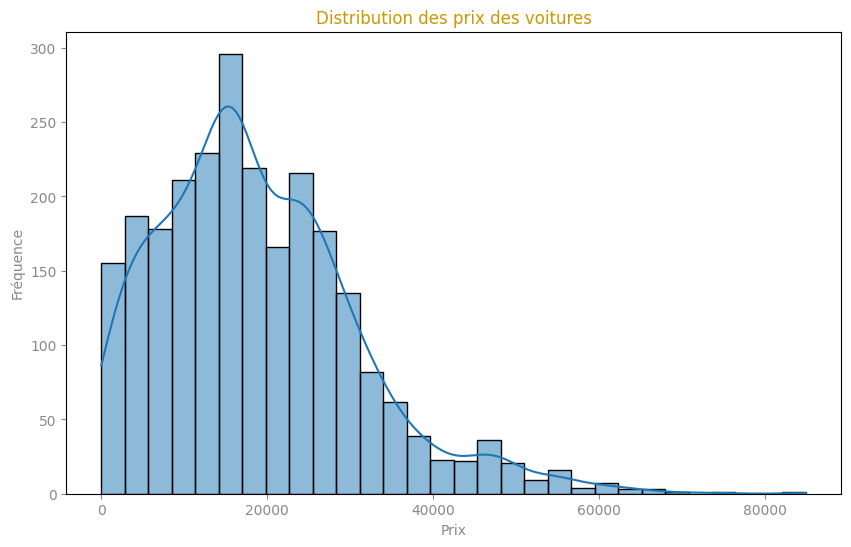

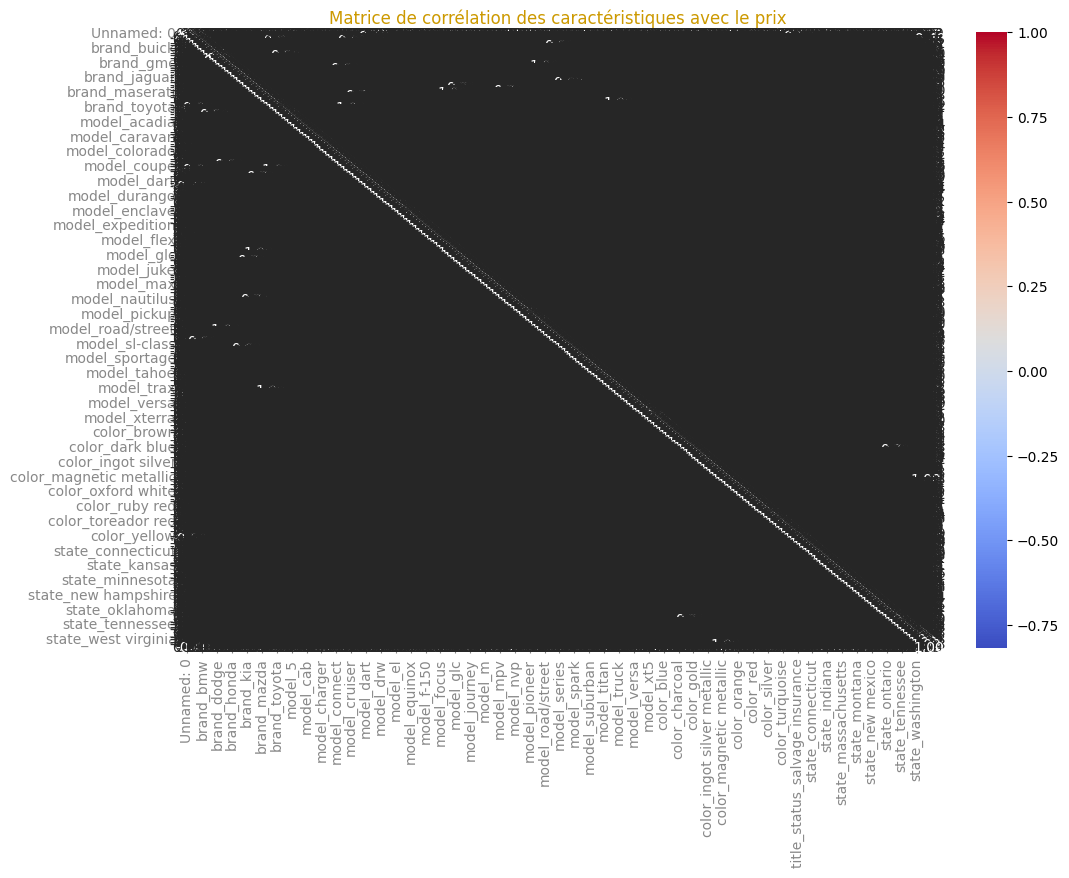

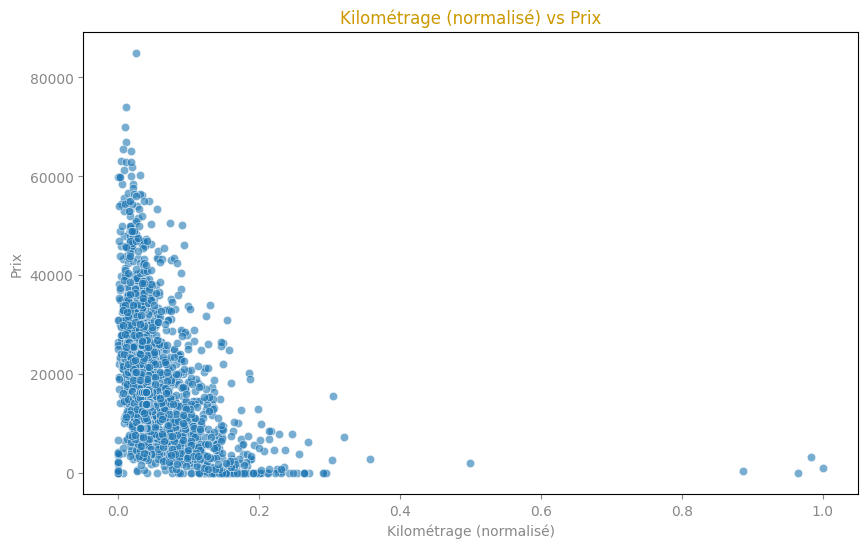

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Supposons que 'prix' est votre variable cible et est présente dans df_encoded
if 'price' in df_encoded.columns:
    # Distribution du prix
    plt.figure(figsize=(10, 6))
    sns.histplot(df_encoded['price'], kde=True, bins=30)
    plt.title('Distribution des prix des voitures', color='#cc9900')
    plt.xlabel('Prix', color='#888888')
    plt.ylabel('Fréquence', color='#888888')
    plt.tick_params(colors='#888888')
    plt.show()

    # Corrélation des variables numériques avec le prix
    # Sélectionnez les colonnes numériques pertinentes pour la corrélation
    correlation_cols = [col for col in df_encoded.columns if pd.api.types.is_numeric_dtype(df_encoded[col]) and col != 'price']
    
    if correlation_cols:
        plt.figure(figsize=(12, 8))
        sns.heatmap(df_encoded[correlation_cols + ['price']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
        plt.title('Matrice de corrélation des caractéristiques avec le prix', color='#cc9900')
        plt.tick_params(colors='#888888')
        plt.show()
    else:
        print("\nAvertissement: Aucune colonne numérique identifiée pour la matrice de corrélation.")

    # Exemple de relation Kilometrage vs Prix (après normalisation si appliquée)
    if 'mileage' in df_encoded.columns:
        plt.figure(figsize=(10, 6))
        sns.scatterplot(x='mileage', y='price', data=df_encoded, alpha=0.6)
        plt.title('Kilométrage (normalisé) vs Prix', color='#cc9900')
        plt.xlabel('Kilométrage (normalisé)', color='#888888')
        plt.ylabel('Prix', color='#888888')
        plt.tick_params(colors='#888888')
        plt.show()
else:
    print("\nErreur: La colonne 'prix' n'a pas été trouvée dans le jeu de données encodé.")


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
# import xgboost as xgb # Décommenter si vous avez installé XGBoost (pip install xgboost)
import numpy as np

# Supposons que 'prix' est votre variable cible
if 'price' in df_encoded.columns:
    X = df_encoded.drop('price', axis=1)
    y = df_encoded['price']

    # Division des données en ensembles d'entraînement et de test
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    print(f"\nForme de X_train: {X_train.shape}")
    print(f"Forme de X_test: {X_test.shape}")
    print(f"Forme de y_train: {y_train.shape}")
    print(f"Forme de y_test: {y_test.shape}")

    # Initialisation et entraînement des modèles
    print("\n--- Entraînement des modèles ---")

    # Régression Linéaire
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    print("Modèle de Régression Linéaire entraîné.")

    # K-Nearest Neighbors
    knn_model = KNeighborsRegressor()
    knn_model.fit(X_train, y_train)
    print("Modèle K-Neighbors entraîné.")

    # Random Forest Regressor
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_model.fit(X_train, y_train)
    print("Modèle Random Forest entraîné.")

    # Gradient Boosting Regressor
    gbr_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
    gbr_model.fit(X_train, y_train)
    print("Modèle Gradient Boosting entraîné.")


else:
    print("\nErreur: Impossible de diviser les données. La colonne 'prix' est manquante.")
    exit()




Forme de X_train: (1999, 249)
Forme de X_test: (500, 249)
Forme de y_train: (1999,)
Forme de y_test: (500,)

--- Entraînement des modèles ---
Modèle de Régression Linéaire entraîné.
Modèle K-Neighbors entraîné.
Modèle Random Forest entraîné.
Modèle Gradient Boosting entraîné.


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Fonction pour évaluer et afficher les métriques
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"\n--- Évaluation du modèle: {model_name} ---")
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R-squared: {r2:.2f}")
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

metrics_lr = evaluate_model(lr_model, X_test, y_test, "Régression Linéaire")
metrics_knn = evaluate_model(knn_model, X_test, y_test, "K-Neighbors")
metrics_rf = evaluate_model(rf_model, X_test, y_test, "Random Forest")
metrics_gbr = evaluate_model(gbr_model, X_test, y_test, "Gradient Boosting")





--- Évaluation du modèle: Régression Linéaire ---
MSE: 48893573.77
RMSE: 6992.39
MAE: 4715.25
R-squared: 0.69

--- Évaluation du modèle: K-Neighbors ---
MSE: 85324241.51
RMSE: 9237.11
MAE: 6361.84
R-squared: 0.46

--- Évaluation du modèle: Random Forest ---
MSE: 40309427.66
RMSE: 6348.97
MAE: 4063.19
R-squared: 0.75

--- Évaluation du modèle: Gradient Boosting ---
MSE: 50238753.19
RMSE: 7087.93
MAE: 4994.37
R-squared: 0.68


In [39]:
from sklearn.model_selection import GridSearchCV

# Exemple d'optimisation avec RandomForestRegressor
# Définir la grille de paramètres à tester
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

# Initialiser GridSearchCV
grid_search = GridSearchCV(estimator=rf_model, # Utilisez votre meilleur modèle ici
                           param_grid=param_grid,
                           cv=3, # Validation croisée à 3 plis
                           scoring='neg_mean_squared_error', # Optimiser pour le RMSE
                           n_jobs=-1, # Utiliser tous les cœurs du CPU
                           verbose=1)

# Exécuter la recherche
print("\n--- Optimisation des hyperparamètres (GridSearchCV) ---")
grid_search.fit(X_train, y_train)

# Afficher les meilleurs paramètres et le meilleur score
print(f"\nMeilleurs paramètres trouvés: {grid_search.best_params_}")
print(f"Meilleur score (RMSE sur validation): {np.sqrt(-grid_search.best_score_):.2f}")

# Utiliser le meilleur modèle optimisé
best_tuned_model = grid_search.best_estimator_
evaluate_model(best_tuned_model, X_test, y_test, "Modèle Random Forest Optimisé")



--- Optimisation des hyperparamètres (GridSearchCV) ---
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Meilleurs paramètres trouvés: {'max_depth': 30, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur score (RMSE sur validation): 6934.82

--- Évaluation du modèle: Modèle Random Forest Optimisé ---
MSE: 40258682.08
RMSE: 6344.97
MAE: 4079.95
R-squared: 0.75


{'MSE': 40258682.07968736,
 'RMSE': np.float64(6344.972977065178),
 'MAE': 4079.9497687653698,
 'R2': 0.74599083216447}

In [49]:
import joblib

# Sauvegarde du modèle (par exemple, le modèle Random Forest optimisé si l'optimisation a été faite, sinon rf_model)
joblib.dump(best_tuned_model if 'best_tuned_model' in locals() else rf_model, 'car_price_prediction_model.pkl')
print("\nModèle sauvegardé sous 'car_price_prediction_model.pkl'.")



# Chargement du modèle et prédiction sur de nouvelles données
loaded_model = joblib.load('car_price_prediction_model.pkl')

#nouvelle voitures
new_car = {
    'year': 2018,
    'mileage': 45000,

    # Marque
    'brand_ford': 1,

    # Modèle
    'model_mustang': 1,

    # Couleur
    'color_black': 1,

    # État (USA)
    'state_texas': 1,

    # Statut du titre
    'title_status_salvage insurance': 0,
}

# Convertir en DataFrame
new_car_df = pd.DataFrame([new_car])


# Assurez-vous que les colonnes de new_car_df sont exactement dans le même ordre que X_train
new_car_df = new_car_df.reindex(columns=X_train.columns, fill_value=0)

# Prédiction
predicted_price = loaded_model.predict(new_car_df)[0]
print(f"\nPrix prédit pour la nouvelle voiture: {predicted_price:.2f} $")



Modèle sauvegardé sous 'car_price_prediction_model.pkl'.

Prix prédit pour la nouvelle voiture: 12648.52 $
